# DES Y3 data products: review

The Y3 counterpart of `notebooks/desy6/products.ipynb`, on the frozen Y3 products of `configs/desy3/v18/default.yaml`,
to compare the two surveys. It writes nothing; plots and tests are the Y6 notebook's.

Y3 has no provenance file, no coverage map in its pixel file, no values file and no MagLim weights. The coverage is
rebuilt from the Y3 MagLim mask as `pixel_file.ipynb` did, the values come from the config, and the MagLim weights
are 1.

Run it in `torch_env` (healpy, h5py, astropy, matplotlib, msfm from this checkout).

In [1]:
from pathlib import Path

import h5py
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits

import msfm
from msfm.utils import files, filenames, lensing

REPO = Path(msfm.__file__).resolve().parents[1]
CONFIG = REPO / "configs/desy3/v18/default.yaml"
conf = files.load_config(str(CONFIG))
PREFIX = "desy3"
CACHE = REPO / "data/desy3/cache"

n_side = conf["analysis"]["n_side"]
n_pix = hp.nside2npix(n_side)
pix_area = hp.nside2pixarea(n_side, degrees=True)

survey_labels = {"metacal": [f"metacal{i}" for i in range(1, 5)], "maglim": [f"maglim{i}" for i in range(1, 7)]}
used = {sample: conf["survey"][sample]["z_bins"] for sample in survey_labels}
print(used)

{'metacal': ['metacal1', 'metacal2', 'metacal3', 'metacal4'], 'maglim': ['maglim1', 'maglim2', 'maglim3', 'maglim4']}


## n(z)

The Y3 n(z). Dotted lines are survey bins the config does not use. The grid starts at z = 0.005.

grid starts at z = 0.005; n(z) there: {'metacal1': np.float64(1.3350632414186527e-05), 'metacal2': np.float64(1.2957716328332969e-05), 'metacal3': np.float64(9.223728781076355e-06), 'metacal4': np.float64(2.477003369509762e-05), 'maglim1': np.float64(8.486025950143943e-05), 'maglim2': np.float64(3.409117487068438e-05), 'maglim3': np.float64(4.237279309650803e-05), 'maglim4': np.float64(3.800930861773533e-05), 'maglim5': np.float64(3.194263778788678e-05), 'maglim6': np.float64(3.912808490501933e-05)}


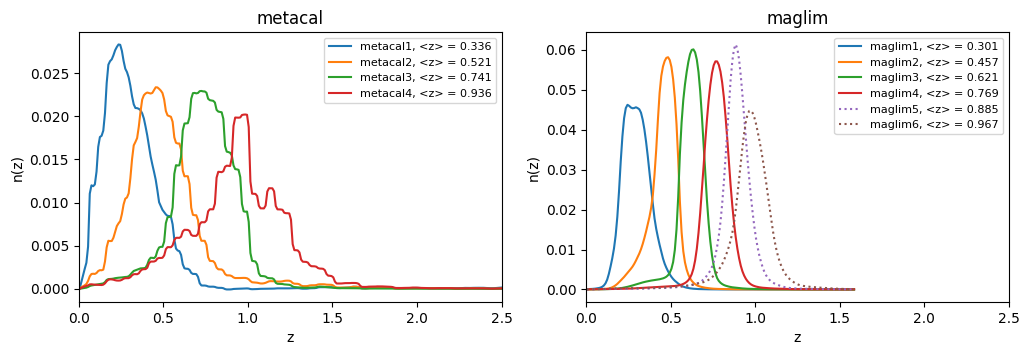

In [2]:
nz_dir = str(REPO / conf["dirs"]["redshift_distributions"])
mean_z, nz_at_grid_start = {}, {}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for ax, (sample, labels) in zip(axes, survey_labels.items()):
    for i_bin, label in enumerate(labels, start=1):
        z, nz = np.loadtxt(filenames.get_filename_z_distribution(nz_dir, sample, i_bin, prefix=PREFIX)).T
        mean_z[label], nz_at_grid_start[label] = np.sum(z * nz) / np.sum(nz), nz[0]
        style = "-" if label in used[sample] else ":"
        ax.plot(z, nz, style, label=f"{label}, <z> = {mean_z[label]:.3f}")
    ax.set(xlabel="z", ylabel="n(z)", title=sample, xlim=(0, 2.5))
    ax.legend(fontsize=8)

print(f"grid starts at z = {z[0]}; n(z) there: {nz_at_grid_start}")

## Footprint and the coverage threshold

The pixel file stores no coverage, so it is rebuilt here from the MagLim mask at nside 4096, rotated at that
resolution and degraded to nside 512, and checked against the stored footprint. The threshold 0.72 makes the
footprint area match the mask area. Pixels below the threshold leave the footprint, at its edges and as interior holes
(pixels below the threshold whose eight neighbours are all in the footprint).

In [3]:
# the Y3 pixel file stores no coverage: rebuild it as notebooks/desy3/pixel_file.ipynb did (nside 4096 mask,
# rotated at 4096, ud_graded to 512) and check that it reproduces the stored footprint
mask_file = REPO / "data/desy3/deprecated/y3_gold_2.2.1_RING_joint_redmagic_v0.5.1_wide_maglim_v2.2_mask.fits.gz"
hpix = fits.getdata(mask_file)["HPIX"]
mask_4096 = np.zeros(hp.nside2npix(4096))
mask_4096[hpix] = 1
rotation = conf["analysis"]["footprint"]["rotation"]
rotator = hp.Rotator(rot=(0, -rotation["y_rad"], rotation["z_rad"]), eulertype="Y", deg=False)
coverage = hp.ud_grade(rotator.rotate_map_pixel(mask_4096), nside_out=n_side, pess=False)
threshold = 0.72
attrs = {"area_deg2": hpix.size * hp.nside2pixarea(4096, degrees=True), "coverage_threshold": threshold}

with h5py.File(REPO / conf["files"]["pixels"], "r") as f:
    patches = f["metacal/patches/metacal1"][:]
    data_vec = f["data_vec"][:]
footprint = patches[0]
rebuilt = np.flatnonzero(coverage >= threshold)
print(f"rebuilt footprint == stored footprint: {np.array_equal(rebuilt, np.sort(footprint))} "
      f"({np.setxor1d(rebuilt, footprint).size} pixels differ)")
for key, value in attrs.items():
    print(f"{key}: {value}")

in_footprint = np.zeros(n_pix, dtype=bool)
in_footprint[footprint] = True
print(
    f"\nfootprint: {footprint.size} pixels, {footprint.size * pix_area:.1f} deg^2 (mask {attrs['area_deg2']:.3f}), "
    f"mean coverage {coverage[footprint].mean():.4f}; data vector {data_vec.size} pixels"
)
out = ~in_footprint
print(f"mask area in the footprint {coverage[footprint].sum() * pix_area:.1f} deg^2, "
      f"outside {coverage[out].sum() * pix_area:.1f} deg^2, "
      f"fraction inside {coverage[footprint].sum() / coverage.sum():.4f}")

neighbours = hp.get_all_neighbours(n_side, np.arange(n_pix))
surrounded = np.all(in_footprint[neighbours] | (neighbours < 0), axis=0)
holes = surrounded & ~in_footprint
print(f"{holes.sum()} holes; their coverage: {np.round(np.sort(coverage[holes]), 3)[:30]}")

rebuilt footprint == stored footprint: True (0 pixels differ)
area_deg2: 4183.462862857213
coverage_threshold: 0.72

footprint: 318616 pixels, 4178.3 deg^2 (mask 4183.463), mean coverage 0.9208; data vector 458752 pixels
mask area in the footprint 3847.3 deg^2, outside 336.1 deg^2, fraction inside 0.9197
6558 holes; their coverage: [0.028 0.033 0.038 0.041 0.042 0.055 0.059 0.066 0.072 0.077 0.087 0.091
 0.1   0.112 0.113 0.115 0.115 0.117 0.119 0.122 0.124 0.127 0.132 0.147
 0.148 0.148 0.149 0.154 0.155 0.158]


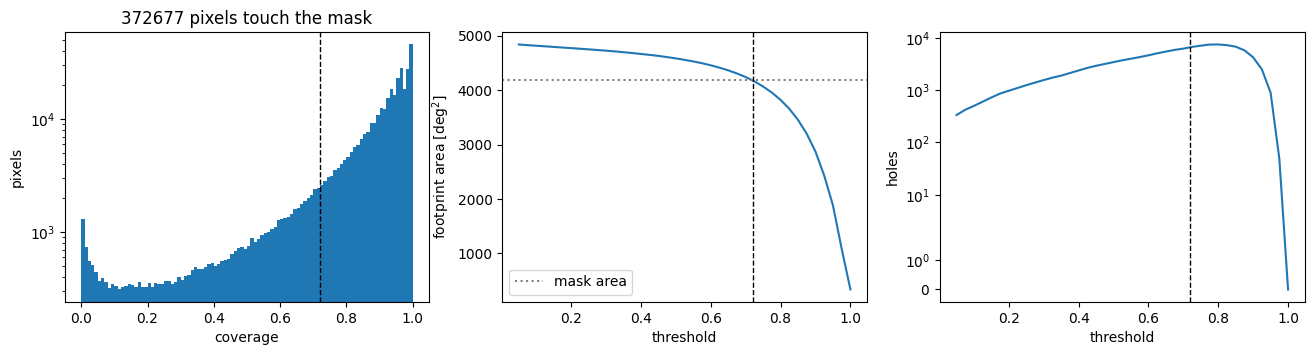

In [4]:
touched = coverage[coverage > 0]
thresholds = np.linspace(0.05, 1, 39)

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 3.5))
ax0.hist(touched, bins=100, log=True)
ax0.set(xlabel="coverage", ylabel="pixels", title=f"{touched.size} pixels touch the mask")

ax1.plot(thresholds, [np.sum(coverage >= t) * pix_area for t in thresholds])
ax1.axhline(attrs["area_deg2"], color="gray", ls=":", label="mask area")
ax1.set(xlabel="threshold", ylabel="footprint area [deg$^2$]")
ax1.legend()

n_holes = [np.sum(np.all((coverage >= t)[neighbours] | (neighbours < 0), axis=0) & (coverage < t)) for t in thresholds]
ax2.plot(thresholds, n_holes)
ax2.set(xlabel="threshold", ylabel="holes", yscale="symlog")

for ax in (ax0, ax1, ax2):
    ax.axvline(threshold, color="k", ls="--", lw=1)

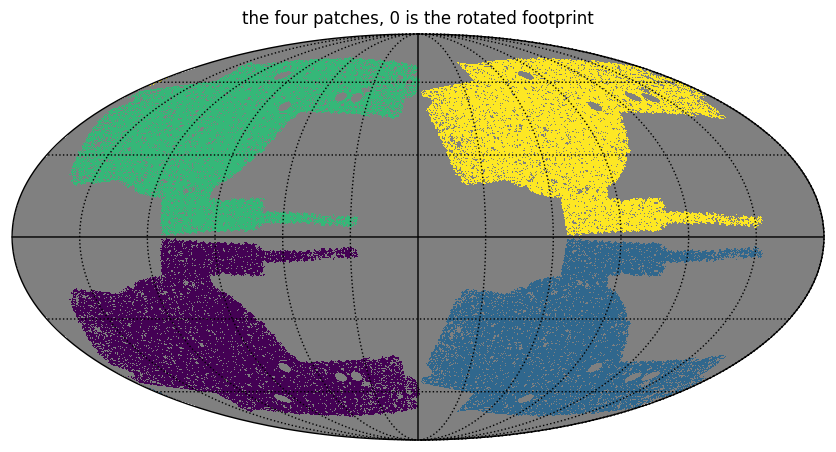

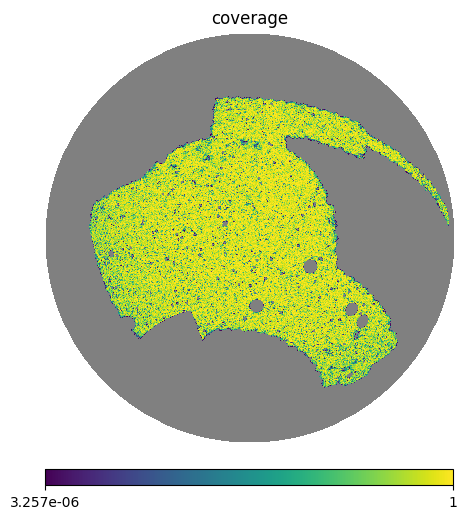

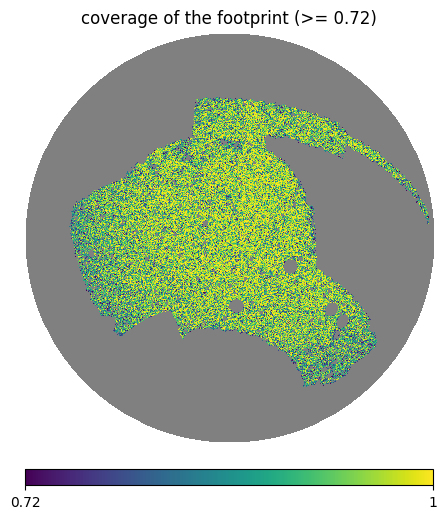

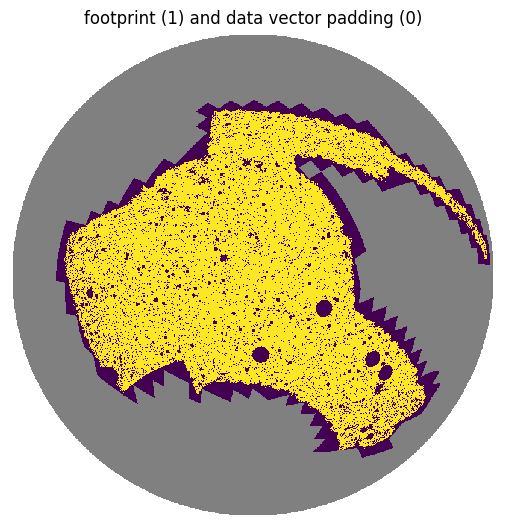

In [5]:
patch_map = np.full(n_pix, hp.UNSEEN)
for i, patch in enumerate(patches):
    patch_map[patch] = i
hp.mollview(patch_map, title="the four patches, 0 is the rotated footprint", cbar=False)
hp.graticule()

# centre of the rotated footprint, for the zooms below
lon, lat = hp.vec2ang(np.mean(hp.pix2vec(n_side, footprint), axis=1), lonlat=True)
centre = (float(np.ravel(lon)[0]), float(np.ravel(lat)[0]))

hp.orthview(np.where(coverage > 0, coverage, hp.UNSEEN), rot=centre, half_sky=True, title="coverage")
kept = np.full(n_pix, hp.UNSEEN)
kept[footprint] = coverage[footprint]
hp.orthview(kept, rot=centre, half_sky=True, title=f"coverage of the footprint (>= {threshold})", min=threshold, max=1)
padding = np.full(n_pix, hp.UNSEEN)
padding[hp.nest2ring(n_side, data_vec)] = 0
padding[footprint] = 1
hp.orthview(padding, rot=centre, half_sky=True, title="footprint (1) and data vector padding (0)", cbar=False)

## Survey values

The config's values next to the same quantities recomputed from the maps the way the Y6 step `values` does them.

In [6]:
source_count = np.load(CACHE / "desy3_metacal_count.npy")
lens_count = np.load(CACHE / "desy3_maglim_count.npy")
footprint_area = footprint.size * pix_area
R = np.array(conf["survey"]["metacal"]["R_gamma"]) + np.array(conf["survey"]["metacal"]["R_s"])
shear = conf["survey"]["metacal"]["shear_bias"]["multiplicative"]

print(f"Aeff = {conf['survey']['Aeff']} deg^2 (mask {attrs['area_deg2']:.3f}), footprint {footprint_area:.1f} deg^2\n")
print(f"{'bin':9s} {'n_gal config':>13s} {'n_gal maps':>11s} {'R':>7s} {'m mu':>8s} {'m sigma':>8s}  [arcmin^-2]")
for i, label in enumerate(survey_labels["metacal"]):
    recomputed = source_count[footprint, i].sum() / footprint_area / 60**2
    print(f"{label:9s} {conf['survey']['metacal']['n_gal'][i] / 60**2:13.4f} {recomputed:11.4f} {R[i]:7.4f} "
          f"{shear['mu'][i]:8.4f} {shear['sigma'][i]:8.4f}")
for j, label in enumerate(used["maglim"]):
    recomputed = lens_count[footprint, j].sum() / footprint_area / 60**2
    print(f"{label:9s} {conf['survey']['maglim']['n_gal'][j] / 60**2:13.4f} {recomputed:11.4f}")

Aeff = 4143 deg^2 (mask 4183.463), footprint 4178.3 deg^2

bin        n_gal config  n_gal maps       R     m mu  m sigma  [arcmin^-2]
metacal1         1.5294      1.5294  0.7682  -0.0063   0.0091
metacal2         1.5516      1.5516  0.7265  -0.0198   0.0078
metacal3         1.5273      1.5273  0.7013  -0.0241   0.0076
metacal4         1.5496      1.5496  0.6299  -0.0369   0.0076
maglim1          0.1369      0.1369
maglim2          0.0978      0.0978
maglim3          0.0994      0.0994
maglim4          0.1328      0.1328


## Maps

The cached maps of `build_des.ipynb`. The mean shear is not subtracted; it is printed here next to the per-pixel
rms.

In [7]:
gamma = np.load(CACHE / "desy3_metacal_gamma_e1p_e2m.npy")  # (n_pix, 4, 2)
# Y3 MagLim has no per-galaxy weights: the weighted count is the count
lens_weighted = lens_count
survey_labels["maglim"] = used["maglim"]

for i, label in enumerate(survey_labels["metacal"]):
    n = source_count[:, i]
    g = gamma[footprint, i]
    mean = np.average(g, weights=n[footprint], axis=0)
    rms = np.sqrt(np.average(g**2, weights=n[footprint], axis=0))
    print(
        f"{label}: {n[footprint].sum() / n.sum():.4f} of {n.sum()} galaxies in the footprint, "
        f"mean (g1, g2) = ({mean[0]:+.2e}, {mean[1]:+.2e}), rms ({rms[0]:.3f}, {rms[1]:.3f})"
    )
for j, label in enumerate(survey_labels["maglim"]):
    n = lens_count[:, j]
    print(f"{label}: {n[footprint].sum() / n.sum():.4f} of {n.sum():.0f} galaxies in the footprint")

metacal1: 0.9224 of 24940465 galaxies in the footprint, mean (g1, g2) = (+4.42e-04, -1.03e-04), rms (0.031, 0.031)
metacal2: 0.9232 of 25280405 galaxies in the footprint, mean (g1, g2) = (+4.54e-04, +3.70e-05), rms (0.033, 0.033)
metacal3: 0.9230 of 24891859 galaxies in the footprint, mean (g1, g2) = (+5.18e-04, +1.06e-04), rms (0.033, 0.033)
metacal4: 0.9290 of 25091297 galaxies in the footprint, mean (g1, g2) = (+6.08e-04, +2.12e-04), rms (0.039, 0.039)
maglim1: 0.9207 of 2236473 galaxies in the footprint
maglim2: 0.9194 of 1599500 galaxies in the footprint
maglim3: 0.9192 of 1627413 galaxies in the footprint
maglim4: 0.9182 of 2175184 galaxies in the footprint


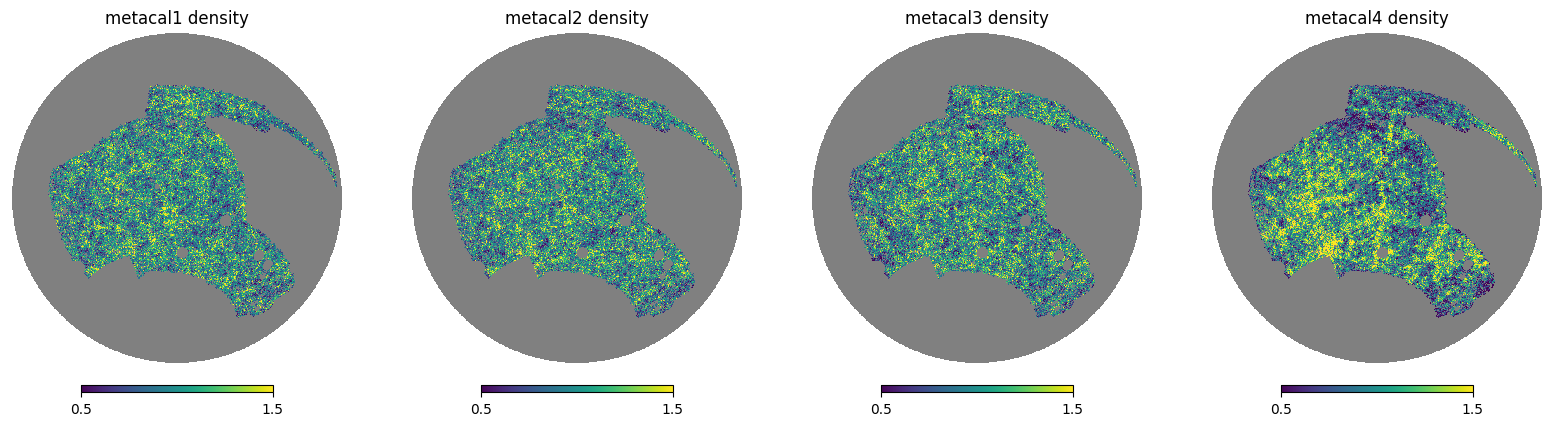

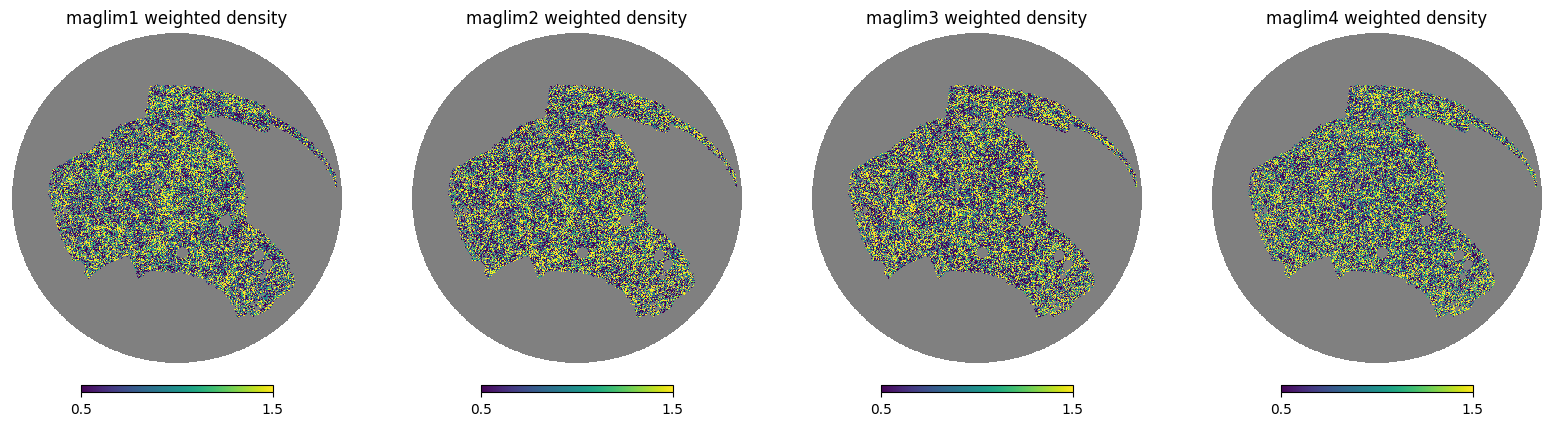

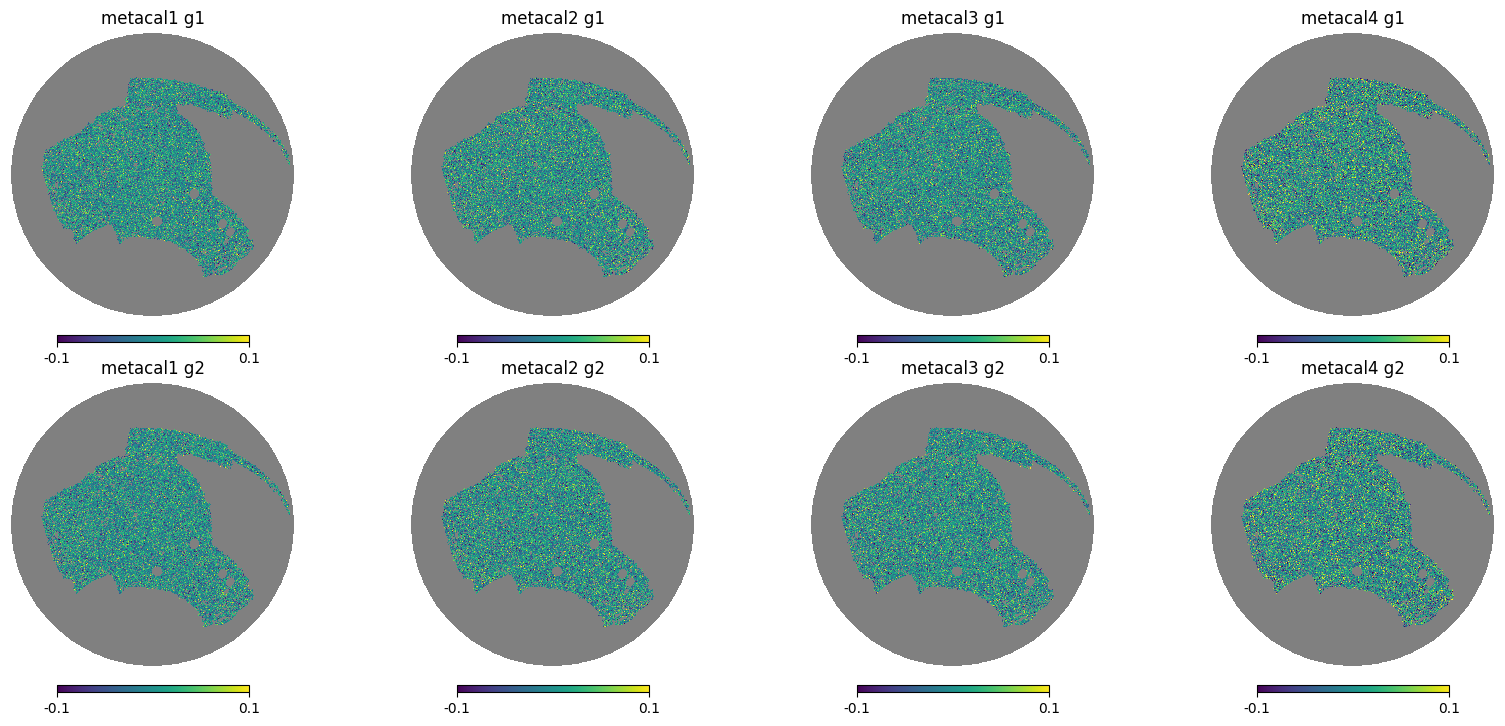

In [8]:
def show(values, title, sub, **kwargs):
    m = np.full(n_pix, hp.UNSEEN)
    m[footprint] = values[footprint]
    hp.orthview(m, rot=centre, half_sky=True, title=title, sub=sub, **kwargs)


# density relative to the footprint mean, per unit covered area
plt.figure(figsize=(16, 4))
for i, label in enumerate(survey_labels["metacal"]):
    n = source_count[:, i] / np.maximum(coverage, 1e-3)
    show(n / n[footprint].mean(), f"{label} density", (1, 4, i + 1), min=0.5, max=1.5)

plt.figure(figsize=(16, 4))
for j, label in enumerate(survey_labels["maglim"]):
    n = lens_weighted[:, j] / np.maximum(coverage, 1e-3)
    show(n / n[footprint].mean(), f"{label} weighted density", (1, 4, j + 1), min=0.5, max=1.5)

plt.figure(figsize=(16, 7))
for i, label in enumerate(survey_labels["metacal"]):
    for c in range(2):
        show(gamma[:, i, c], f"{label} g{c + 1}", (2, 4, c * 4 + i + 1), min=-0.1, max=0.1)

## Noise file

The shape catalog per source bin of `noise_file.ipynb`, from the first 2 million rows of each: the
response-corrected ellipticities and the weights that the `count` shape-noise model resamples.

metacal1: 24940465 galaxies (count map 24940465), weighted rms e/R = [0.25142511 0.25155665]
metacal2: 25280405 galaxies (count map 25280405), weighted rms e/R = [0.26955438 0.26974088]


metacal3: 24891859 galaxies (count map 24891859), weighted rms e/R = [0.26516039 0.26556901]
metacal4: 25091297 galaxies (count map 25091297), weighted rms e/R = [0.31259172 0.31265842]


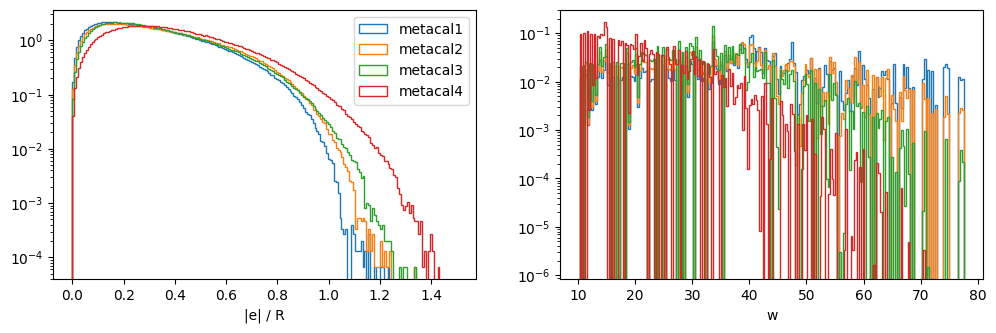

In [9]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 3.5))
with h5py.File(REPO / conf["files"]["noise"], "r") as f:
    for i, label in enumerate(survey_labels["metacal"]):
        cat = f[f"{label}/cat"]
        sample = cat[:2_000_000].astype(np.float64)
        e_abs, w = np.hypot(sample[:, 0], sample[:, 1]), sample[:, 2]
        rms = np.sqrt(np.average(sample[:, :2] ** 2, axis=0, weights=w))
        print(f"{label}: {cat.shape[0]} galaxies (count map {source_count[:, i].sum()}), weighted rms e/R = {rms}")
        ax0.hist(e_abs, bins=200, range=(0, 1.5), histtype="step", density=True, label=label)
        ax1.hist(w, bins=200, histtype="step", density=True, label=label)
ax0.set(xlabel="|e| / R", yscale="log")
ax1.set(xlabel="w", yscale="log")
ax0.legend()

## Shear convention: κ_E × δ_g and κ_B × δ_g

The test that validated the Y3 conventions (e1 +1, e2 −1, the ψ rotation of `catalog.py`). κ_E and κ_B come from the footprint-masked shear maps through `lensing.mode_removal`,
as on the observation path; δ_g is the weighted MagLim count per covered area. Expected:

- κ_E × δ_g **positive** where the lens bin lies in front of the source bin. A flip of both e1 and e2 makes it
  negative; a wrong e2 parity pushes it towards zero.
- κ_B × δ_g **null**. A wrong or missing ψ rotation shows up here (−3 to −6σ per band for Y3 without it).

The E/B power alone cannot decide the overall sign. The errors are Gaussian (Knox) from the measured pseudo-spectra,
with the footprint's f_sky, so they ignore the mode coupling between neighbouring bands.

In [10]:
hp_datapath = str(REPO / conf["files"]["healpy_data"])
_, gamma2kappa_fac, _ = lensing.get_kaiser_squires_factors(3 * n_side - 1)
f_sky = in_footprint.mean()
l_max = 3 * n_side - 1
band_edges = np.array([30, 60, 100, 160, 250, 400, 630, 1000])
ell = np.arange(l_max + 1)
n_modes = np.array([np.sum(2 * ell[(ell >= lo) & (ell < hi)] + 1) for lo, hi in zip(band_edges[:-1], band_edges[1:])])


def footprint_only(m):
    """The map inside the footprint with its mean there removed, zero outside."""
    return np.where(in_footprint, m - m[in_footprint].mean(), 0.0)


def bands(cl):
    return np.array([cl[(ell >= lo) & (ell < hi)].mean() for lo, hi in zip(band_edges[:-1], band_edges[1:])])


kappa = {}
for label in used["metacal"]:
    i_survey = survey_labels["metacal"].index(label)
    g1, g2 = (np.where(in_footprint, gamma[:, i_survey, c], 0.0) for c in range(2))
    k_E, k_B = lensing.mode_removal(g1, g2, gamma2kappa_fac, n_side, hp_datapath=hp_datapath, keep_b_mode=True)
    kappa[label] = {"E": footprint_only(k_E.astype(np.float64)), "B": footprint_only(k_B.astype(np.float64))}

delta = {}
for label in used["maglim"]:
    n = lens_weighted[:, survey_labels["maglim"].index(label)]
    n_bar = n[in_footprint].sum() / coverage[in_footprint].sum()
    delta[label] = footprint_only(n / (n_bar * np.maximum(coverage, 1e-3)) - 1)

# band-averaged pseudo-spectra; the Knox error of a cross spectrum needs both autos
auto_kappa = {(label, mode): bands(hp.anafast(k[mode], lmax=l_max)) for label, k in kappa.items() for mode in "EB"}
auto_delta = {label: bands(hp.anafast(d, lmax=l_max)) for label, d in delta.items()}
cross = {}
for source, k in kappa.items():
    for lens, d in delta.items():
        for mode in "EB":
            cl = bands(hp.anafast(k[mode], d, lmax=l_max))
            sigma = np.sqrt((auto_kappa[source, mode] * auto_delta[lens] + cl**2) / (f_sky * n_modes))
            cross[source, lens, mode] = (cl, sigma)
print(f"f_sky = {f_sky:.4f}, {len(cross)} cross spectra in {len(n_modes)} bands")

f_sky = 0.1013, 32 cross spectra in 7 bands


pair                   E S/N   B S/N  B chi2/dof  lens in front
metacal1 x maglim1      16.0     0.7    3.5 / 7  yes
metacal1 x maglim2       7.8     0.7    4.1 / 7  no
metacal1 x maglim3       3.6     0.0    3.2 / 7  no
metacal1 x maglim4       0.7    -2.3    9.3 / 7  no
metacal2 x maglim1      28.9     1.0   13.7 / 7  yes
metacal2 x maglim2      13.0     0.7    5.7 / 7  yes
metacal2 x maglim3       7.7     0.6    3.3 / 7  no
metacal2 x maglim4       4.9    -3.0   13.0 / 7  no
metacal3 x maglim1      48.1     1.8    8.3 / 7  yes
metacal3 x maglim2      32.7     0.7    4.9 / 7  yes
metacal3 x maglim3      13.9     0.0    4.0 / 7  yes
metacal3 x maglim4       6.4     0.3    1.4 / 7  no
metacal4 x maglim1      44.1    -0.6    5.2 / 7  yes
metacal4 x maglim2      35.0     0.8    9.6 / 7  yes
metacal4 x maglim3      23.0     1.4   10.0 / 7  yes
metacal4 x maglim4      15.4     0.2    3.3 / 7  yes


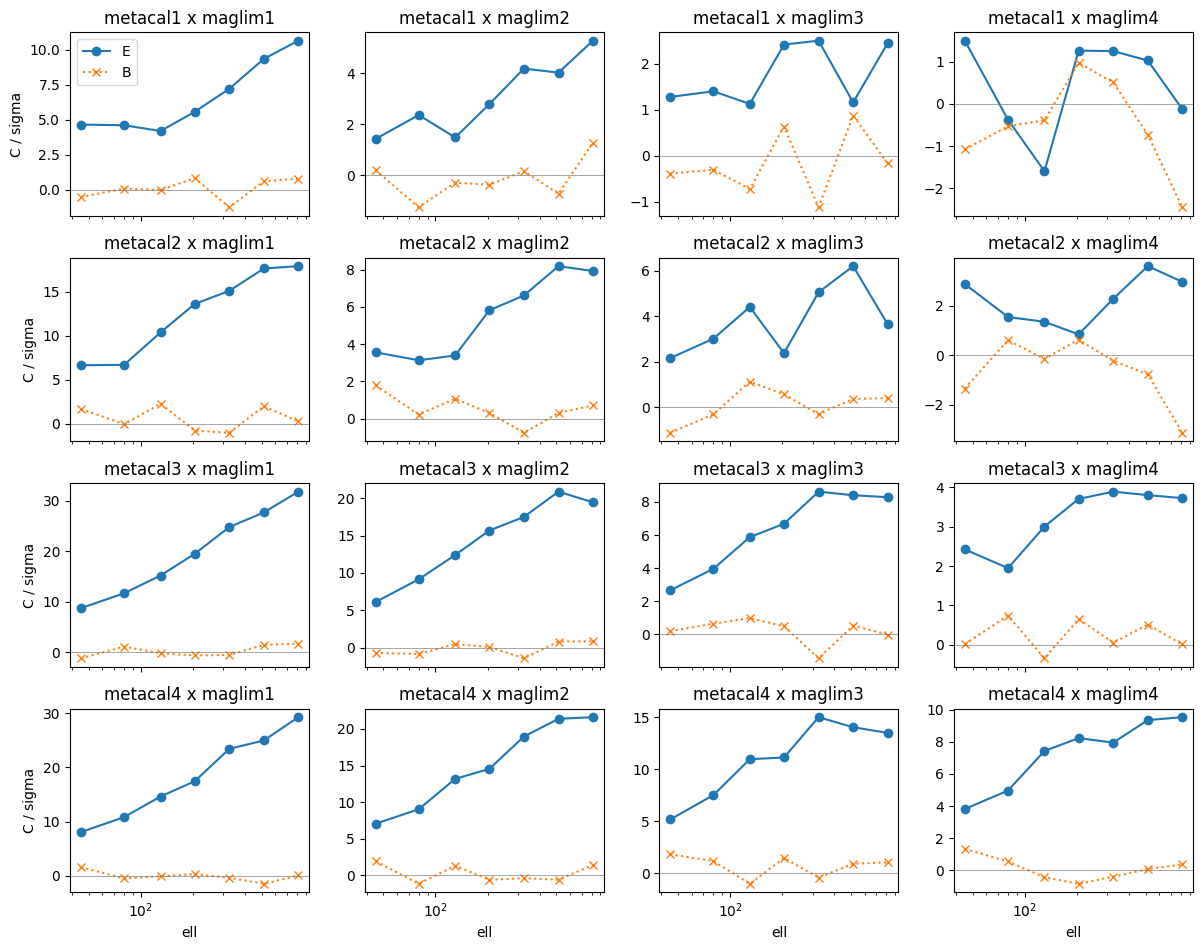

In [11]:
band_centres = 0.5 * (band_edges[:-1] + band_edges[1:])
sources, lenses = list(kappa), list(delta)


def combined(cl, sigma):
    """Inverse-variance weighted mean amplitude over the bands, in units of its error."""
    return np.sum(cl / sigma**2) / np.sqrt(np.sum(1 / sigma**2))


print(f"{'pair':20s} {'E S/N':>7s} {'B S/N':>7s} {'B chi2/dof':>11s}  lens in front")
fig, axes = plt.subplots(len(sources), len(lenses), figsize=(3 * len(lenses), 2.4 * len(sources)), sharex=True)
for r, source in enumerate(sources):
    for c, lens in enumerate(lenses):
        (cl_E, sigma_E), (cl_B, sigma_B) = cross[source, lens, "E"], cross[source, lens, "B"]
        chi2_B = np.sum((cl_B / sigma_B) ** 2)
        front = "yes" if mean_z[lens] < mean_z[source] else "no"
        print(
            f"{source + ' x ' + lens:20s} {combined(cl_E, sigma_E):7.1f} {combined(cl_B, sigma_B):7.1f} "
            f"{chi2_B:6.1f} / {len(n_modes)}  {front}"
        )

        ax = axes[r, c]
        ax.plot(band_centres, cl_E / sigma_E, "o-", label="E")
        ax.plot(band_centres, cl_B / sigma_B, "x:", label="B")
        ax.axhline(0, color="gray", lw=0.5)
        ax.set(xscale="log", title=f"{source} x {lens}")
        if c == 0:
            ax.set_ylabel("C / sigma")
        if r == len(sources) - 1:
            ax.set_xlabel("ell")
axes[0, 0].legend()
fig.tight_layout()